# Traditional approaches

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Simpler, non-deep-learning approaches to detecting change
</div>
<!-- markdownlint-enable MD033 -->

---

You now know what makes two images comparable. This page uses two {term}`Sentinel-2` images of the desert east of Cairo, Egypt, where the country's New Administrative Capital has been built from scratch since the mid-2010s. Between the 2018 and the 2026 image, roads, residential districts, a government quarter and irrigated parks appeared on what was open desert. You will detect these changes with the simplest methods available: subtracting pixel values, and comparing multi-band change vectors. Both work without any labeled training data, which makes them a useful baseline before the deep learning workflow later in this lesson.

---

## 1. Motivation

Not every project has, or needs, a trained deep learning model. Traditional methods are fast, fully interpretable (you can explain exactly why a pixel was flagged), and often good enough for a first look at a study area, or for projects where labeled training data simply is not available. They also give you a baseline: if a deep learning model cannot beat a simple difference image on your data, it is not worth its extra complexity.

---

## 2. Core idea

All methods on this page treat every pixel independently: they compare the spectral values of the same pixel at two dates and flag the pixel as changed if the difference exceeds a threshold. They differ only in *what* they compare:

| Method | Compares | Output | Answers |
| --- | --- | --- | --- |
| {term}`Image differencing <Image Differencing>` | One band (here NIR) | Signed difference | Did this pixel get brighter or darker? |
| Index differencing | A {term}`spectral index <Spectral Index>` (here {term}`NDVI <Normalized Difference Vegetation Index>`) | Signed difference | Did vegetation increase or decrease? |
| {term}`Change Vector Analysis <Change Vector Analysis>` (CVA) | Several measurements at once (here brightness and greenness) | Magnitude and direction | How much did the pixel change, and what kind of change was it? |

Every method ends with the same decision: where to set the threshold. The last steps of this page compare several thresholding rules and show the main weakness all pixel-wise methods share, which the next page's deep learning approach addresses.

---

## 3. Workflow

### A. Download and check the image pair

In [1]:
from pathlib import Path

import geoai
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from skimage.filters import threshold_otsu

DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://data.source.coop/giuz/sds320/L10/data/"
paths = {}
for year in [2018, 2026]:
    filename = f"cairo_nac_s2_{year}.tif"
    paths[year] = DATA_DIR / filename
    if not paths[year].exists():
        geoai.download_file(BASE_URL + filename, output_path=str(paths[year]))

for year, path in paths.items():
    with rasterio.open(path) as src:
        print(f"{year}: {src.count} bands {src.descriptions}")
        print(f"      {src.width} x {src.height} px, {src.res[0]:.0f} m pixels, {src.crs}, dtype {src.dtypes[0]}")

2018: 6 bands ('blue', 'green', 'red', 'nir', 'swir1', 'swir2')
      1500 x 1500 px, 10 m pixels, EPSG:32636, dtype uint16
2026: 6 bands ('blue', 'green', 'red', 'nir', 'swir1', 'swir2')
      1500 x 1500 px, 10 m pixels, EPSG:32636, dtype uint16


Both files contain the same six Sentinel-2 bands in the same order (B2, B3, B4, B8, B11, B12: blue, green, red, {term}`near-infrared <Near-Infrared>`, and two {term}`shortwave infrared <Shortwave Infrared>` bands), on the same 10 m grid and in the same {term}`coordinate reference system <Coordinate Reference System>`. This is the first comparability check from the previous page: pixel-wise methods compare pixel *i* in 2018 with pixel *i* in 2026, so both images must share exactly the same grid. If they did not, you would have to {term}`reproject <Reprojection>` or {term}`resample <Resampling>` one image onto the other first.

In [2]:
def read_reflectance(path):
    """Read all bands and convert the stored integers to reflectance (0-1)."""
    with rasterio.open(path) as src:
        return src.read().astype(np.float32) / 10_000

img_2018 = read_reflectance(paths[2018])
img_2026 = read_reflectance(paths[2026])

BLUE, GREEN, RED, NIR, SWIR1, SWIR2 = range(6)  # 0-based band positions in the array
PIXEL_AREA_KM2 = 10 * 10 / 1e6  # one 10 m pixel in km²

assert img_2018.shape == img_2026.shape
print("Array shape (bands, rows, columns):", img_2018.shape)

Array shape (bands, rows, columns): (6, 1500, 1500)


Sentinel-2 stores reflectance as integers scaled by 10,000, so dividing by 10,000 gives values between 0 and 1. The named constants (`RED`, `NIR`, ...) are 0-based positions in the NumPy array, one less than the 1-based band numbers Rasterio uses: `src.read(4)` and `img_2018[NIR]` are the same band.

### B. Look at both dates first

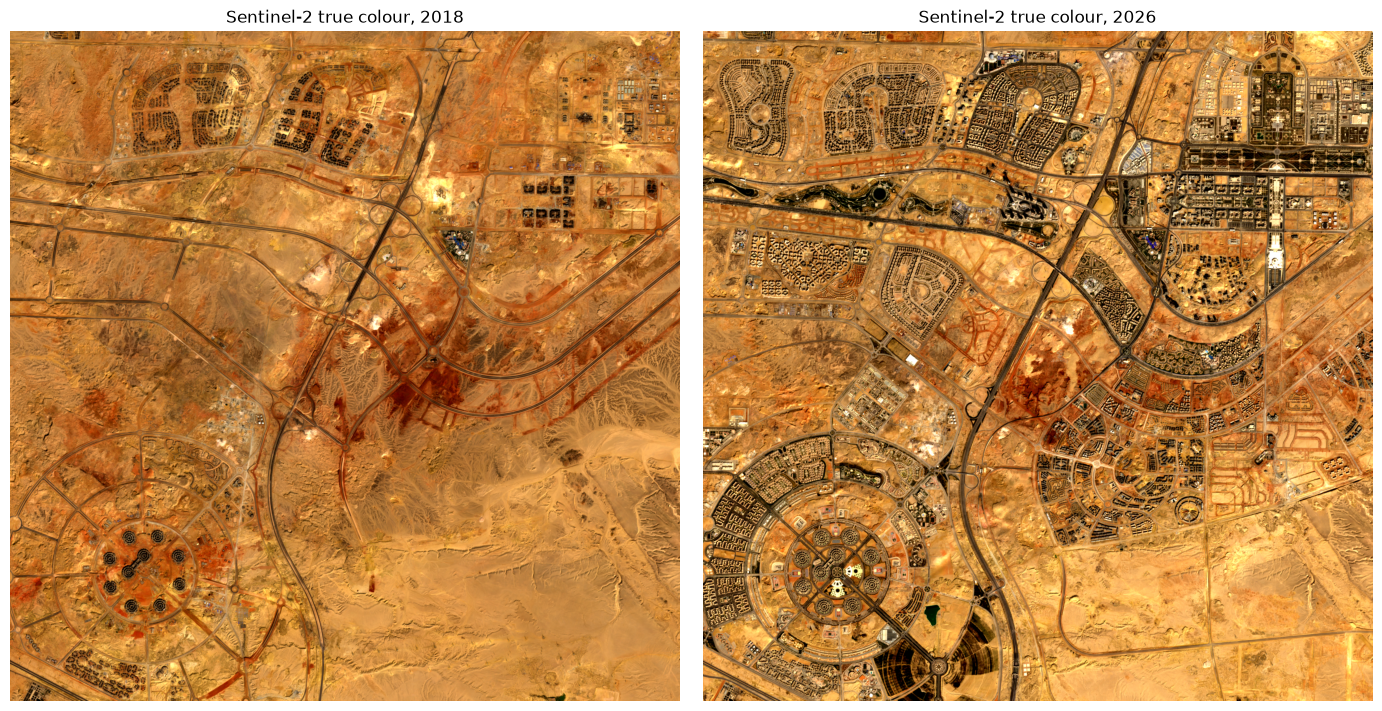

In [3]:
def true_colour(img, lo, hi):
    rgb = np.dstack([img[RED], img[GREEN], img[BLUE]])
    return np.clip((rgb - lo) / (hi - lo), 0, 1)

# One shared stretch for both dates, so colour differences stay visible
stack = np.concatenate([img_2018[[RED, GREEN, BLUE]], img_2026[[RED, GREEN, BLUE]]])
lo, hi = np.percentile(stack, [2, 98])

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, img, year in zip(axes, [img_2018, img_2026], [2018, 2026]):
    ax.imshow(true_colour(img, lo, hi))
    ax.set_title(f"Sentinel-2 true colour, {year}")
    ax.axis("off")
plt.tight_layout()
plt.show()

The street network and building blocks of the new city are obvious in 2026. Look at the open desert too: it appears redder in 2018 than in 2026, although nothing was built there. Differences in atmosphere, sun angle or surface moisture shift the colour of the whole scene, not just the places that changed. Using one shared stretch for both dates, as here, keeps such shifts visible instead of hiding them; stretching each image separately would make the two dates look more similar than they really are.

### C. Image differencing

{term}`Image differencing <Image Differencing>` subtracts one date's pixel values from the other's, then thresholds the result. Here we use the NIR band.

In [4]:
diff = img_2026[NIR] - img_2018[NIR]

centre, std = np.median(diff), diff.std()
threshold = 2 * std
change_mask = np.abs(diff - centre) > threshold

print(f"Difference range: {diff.min():.3f} to {diff.max():.3f}")
print(f"Mean difference: {diff.mean():+.3f}, median difference: {centre:+.3f}")
print(f"Threshold: median ± {threshold:.3f}")
print(f"Changed pixels: {change_mask.sum():,} ({100 * change_mask.mean():.1f}%, {change_mask.sum() * PIXEL_AREA_KM2:.1f} km²)")

Difference range: -0.566 to 0.969
Mean difference: +0.003, median difference: +0.016
Threshold: median ± 0.174
Changed pixels: 137,937 (6.1%, 13.8 km²)


The threshold is centred on the median difference rather than on zero. If the whole scene became slightly brighter between the dates, for example because of haze or drier sand, that shift is not surface change, and centring removes it. This is the simplest form of {term}`radiometric normalization <Radiometric Normalization>`. The median is a better centre than the mean here: the mean is pulled towards the changed pixels themselves, while the median follows the large unchanged majority. It is worth looking at the three pieces together: the raw difference, its histogram, and the resulting mask.

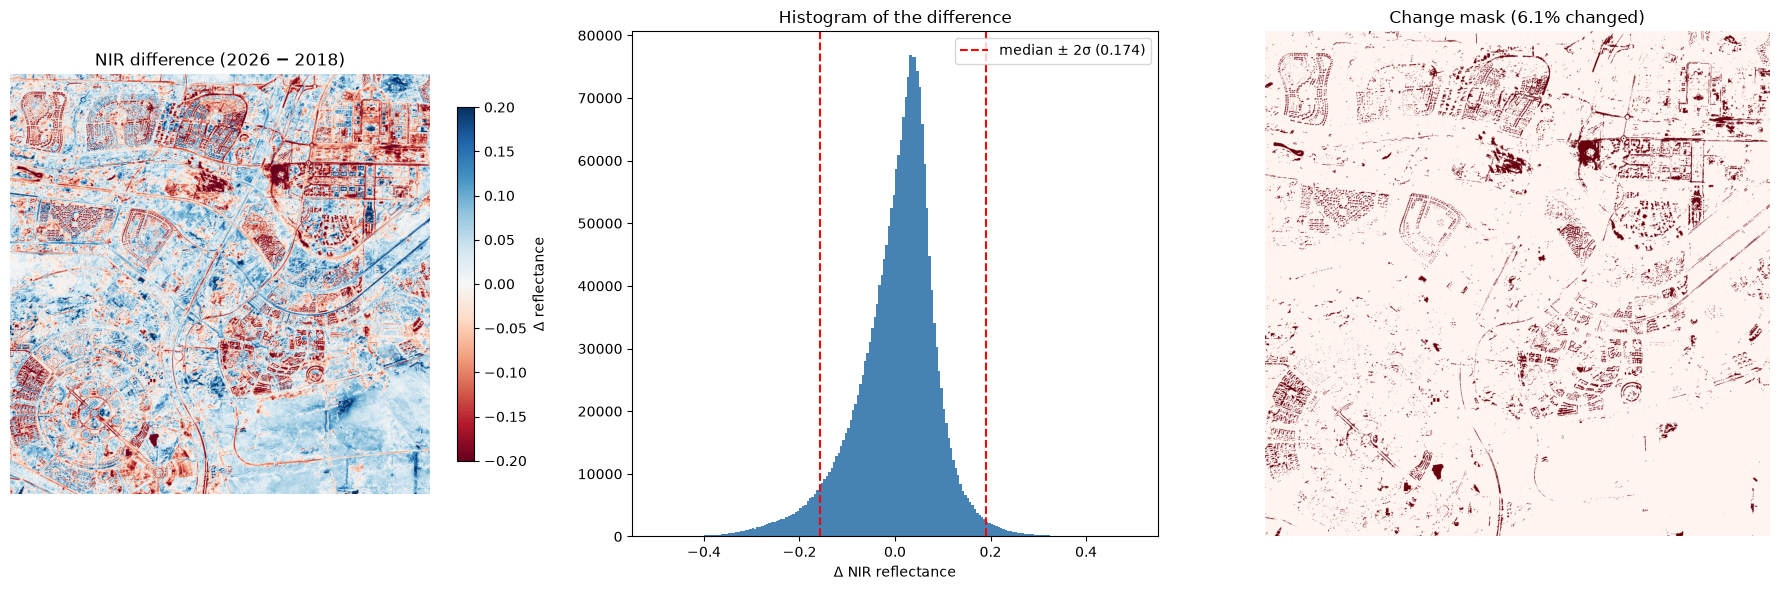

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

im = axes[0].imshow(diff, cmap="RdBu", vmin=-0.2, vmax=0.2)
axes[0].set_title("NIR difference (2026 − 2018)")
axes[0].axis("off")
fig.colorbar(im, ax=axes[0], shrink=0.7, label="Δ reflectance")

axes[1].hist(diff.ravel(), bins=200, range=(-0.5, 0.5), color="steelblue")
axes[1].axvline(centre - threshold, color="red", linestyle="--", label=f"median ± 2σ ({threshold:.3f})")
axes[1].axvline(centre + threshold, color="red", linestyle="--")
axes[1].set_title("Histogram of the difference")
axes[1].set_xlabel("Δ NIR reflectance")
axes[1].legend()

axes[2].imshow(change_mask, cmap="Reds")
axes[2].set_title(f"Change mask ({100 * change_mask.mean():.1f}% changed)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In the difference map, red pixels became darker in NIR and blue pixels brighter. New buildings, asphalt roads and parks appear red: all of them are darker in NIR than the bright sand they replaced. Most of the histogram is one peak: the unchanged desert. Notice that this peak does not sit at zero but slightly to the right, and that the undeveloped southeast has a broad blue tint. The open desert as a whole is a little brighter in 2026, a smooth, large-area shift that comes from surface or atmospheric conditions, not from construction. Changed pixels sit in the tails of the histogram, and the threshold decides where the tails begin.

### D. Index differencing: asking a narrower question

A single band mixes many kinds of change. A {term}`spectral index <Spectral Index>` designed for one surface property lets you ask a narrower question. The {term}`NDVI <Normalized Difference Vegetation Index>` responds to green vegetation, so its difference highlights where vegetation appeared or disappeared.

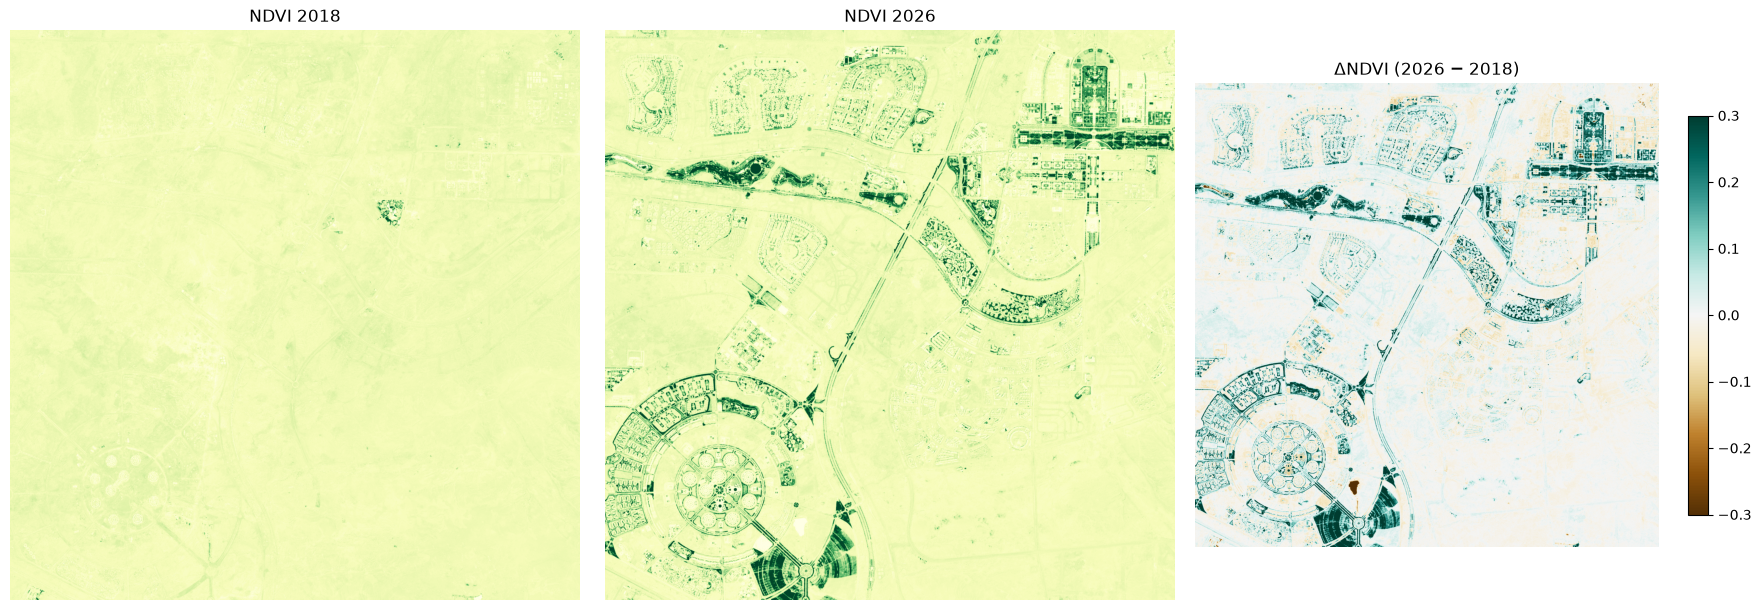

Pixels with ΔNDVI > 0.1: 188,230 (18.8 km²)


In [6]:
def ndvi(img):
    return (img[NIR] - img[RED]) / (img[NIR] + img[RED] + 1e-6)

ndvi_2018, ndvi_2026 = ndvi(img_2018), ndvi(img_2026)
delta_ndvi = ndvi_2026 - ndvi_2018
greening = delta_ndvi > 0.1

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, data, title in zip(axes[:2], [ndvi_2018, ndvi_2026], ["NDVI 2018", "NDVI 2026"]):
    ax.imshow(data, cmap="YlGn", vmin=0, vmax=0.5)
    ax.set_title(title)
    ax.axis("off")
im = axes[2].imshow(delta_ndvi, cmap="BrBG", vmin=-0.3, vmax=0.3)
axes[2].set_title("ΔNDVI (2026 − 2018)")
axes[2].axis("off")
fig.colorbar(im, ax=axes[2], shrink=0.7)
plt.tight_layout()
plt.show()

print(f"Pixels with ΔNDVI > 0.1: {greening.sum():,} ({greening.sum() * PIXEL_AREA_KM2:.1f} km²)")

In 2018 the area was almost free of vegetation (NDVI close to zero everywhere). In 2026, irrigated parks, green corridors and landscaped plots stand out clearly. Index differencing answers "where was vegetation added?" very well, but it is blind to new roads and buildings, which hardly change NDVI in a desert. Choosing the band or index is therefore part of defining your change question, not a technical detail.

### E. Change Vector Analysis

{term}`Change Vector Analysis (CVA) <Change Vector Analysis>` combines several measurements at once. Each pixel's change becomes a vector, with a **magnitude** (how much the pixel changed) and a **direction** (what kind of change it likely represents). The classic form of CVA uses two axes that are easy to interpret: overall **brightness** (here the mean reflectance of all six bands) and **greenness** (here NDVI).

In [7]:
brightness_2018 = img_2018.mean(axis=0)
brightness_2026 = img_2026.mean(axis=0)
d_bright = brightness_2026 - brightness_2018
d_green = delta_ndvi

# Remove the whole-scene shift, and put both axes on the same scale (z-scores)
z_bright = (d_bright - np.median(d_bright)) / d_bright.std()
z_green = (d_green - np.median(d_green)) / d_green.std()

magnitude = np.hypot(z_bright, z_green)                    # length of the change vector
direction = np.degrees(np.arctan2(z_green, z_bright))      # angle: 0° = brighter, 90° = greener

mag_threshold = np.percentile(magnitude, 95)
significant = magnitude > mag_threshold

print(f"Magnitude range: {magnitude.min():.2f} to {magnitude.max():.2f} (in standard deviations)")
print(f"95th percentile threshold: {mag_threshold:.2f}")
print(f"Significant change pixels: {significant.sum():,}")

Magnitude range: 0.00 to 14.38 (in standard deviations)
95th percentile threshold: 3.03
Significant change pixels: 112,500


Brightness and NDVI have different units and ranges, so each difference is first converted to a z-score (subtract its median, as in step C, and divide by its standard deviation). Without this step, whichever axis happens to have larger numbers would dominate both magnitude and direction.

The direction tells you where the vector points. Dividing the circle into four sectors gives four typical kinds of change:

| Direction | Sector | Typical meaning here |
| --- | --- | --- |
| Up (greener) | 45° to 135° | Vegetation gain: irrigated parks, planted trees |
| Right (brighter) | −45° to 45° | Brightening: cleared or levelled ground, fresh concrete, light roofs |
| Left (darker) | beyond ±135° | Darkening: asphalt, dark roofs, shadows of new buildings |
| Down (less green) | −135° to −45° | Vegetation loss |

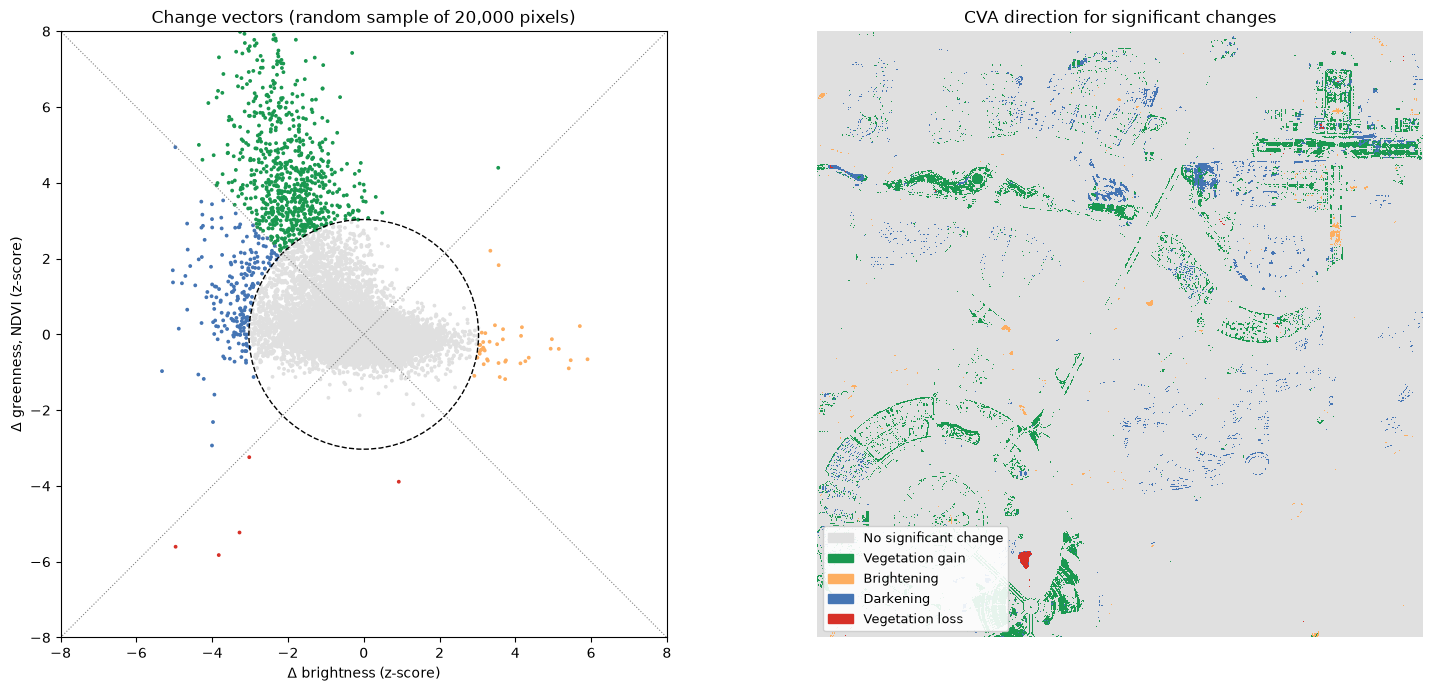

Vegetation gain     8.0 km²
Brightening         0.4 km²
Darkening           2.7 km²
Vegetation loss     0.1 km²


In [8]:
classes = np.select(
    [
        (direction >= 45) & (direction < 135),
        (direction >= -45) & (direction < 45),
        (direction >= 135) | (direction < -135),
    ],
    [1, 2, 3],
    default=4,
)
classes[~significant] = 0  # keep a direction only where the change is significant

names = ["No significant change", "Vegetation gain", "Brightening", "Darkening", "Vegetation loss"]
colours = ["#e0e0e0", "#1a9850", "#fdae61", "#4575b4", "#d73027"]
cmap = ListedColormap(colours)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.1]})

rng = np.random.default_rng(0)
sample = rng.choice(z_bright.size, 20_000, replace=False)
axes[0].scatter(
    z_bright.ravel()[sample], z_green.ravel()[sample],
    c=classes.ravel()[sample], cmap=cmap, vmin=0, vmax=4, s=3,
)
for slope in [1, -1]:  # sector boundaries at ±45° and ±135°
    axes[0].plot([-10, 10], [-10 * slope, 10 * slope], color="grey", lw=0.8, ls=":")
axes[0].add_patch(plt.Circle((0, 0), mag_threshold, fill=False, color="black", ls="--"))
axes[0].set_xlim(-8, 8)
axes[0].set_ylim(-8, 8)
axes[0].set_aspect("equal")
axes[0].set_xlabel("Δ brightness (z-score)")
axes[0].set_ylabel("Δ greenness, NDVI (z-score)")
axes[0].set_title("Change vectors (random sample of 20,000 pixels)")

axes[1].imshow(classes, cmap=cmap, vmin=0, vmax=4, interpolation="nearest")
axes[1].set_title("CVA direction for significant changes")
axes[1].axis("off")
axes[1].legend(
    handles=[Patch(color=c, label=n) for c, n in zip(colours, names)],
    loc="lower left", fontsize=9, framealpha=0.9,
)
plt.tight_layout()
plt.show()

for value, name in enumerate(names[1:], start=1):
    print(f"{name:16s} {np.sum(classes == value) * PIXEL_AREA_KM2:6.1f} km²")

The scatter plot shows the change vectors themselves. Most pixels form a cloud near the origin (little change); the dashed circle is the magnitude threshold, and only vectors outside it count as significant. Their direction then assigns a type. The largest group points up and slightly to the left: new parks became much greener *and* somewhat darker than the bright desert sand they replaced. Darkening picks up the asphalt roads and dark building blocks, brightening the freshly cleared construction surfaces. All of this comes without a single training label. This is what makes CVA more informative than single-band differencing: it already gives a rough *categorical* answer, although "darkening" is a spectral description, not a land-cover class, and still needs your interpretation.

```{admonition} Why not simply use red and NIR as the two axes?
:class: note
You can build a change vector from any pair of bands. In this desert scene, however, red and NIR almost always change together: when the surface gets brighter or darker, both bands follow. Their change vectors then line up along one diagonal, and the direction carries little extra information. Brightness and greenness are designed to vary more independently, which is why the classic form of CVA uses them.
```

### F. Choosing a threshold

Every method above depends on a threshold. Too low, and the result is flooded with noise; too high, and real changes are missed. Three common rules applied to the same CVA magnitude:

- **Mean + 2 standard deviations**: assumes unchanged pixels form a roughly normal distribution and flags the outliers.
- **95th percentile**: flags a fixed share of the scene (here 5%), regardless of how much actually changed.
- **{term}`Otsu's method <Otsu's Method>`**: searches for the value that best separates the histogram into two groups, without any parameter.

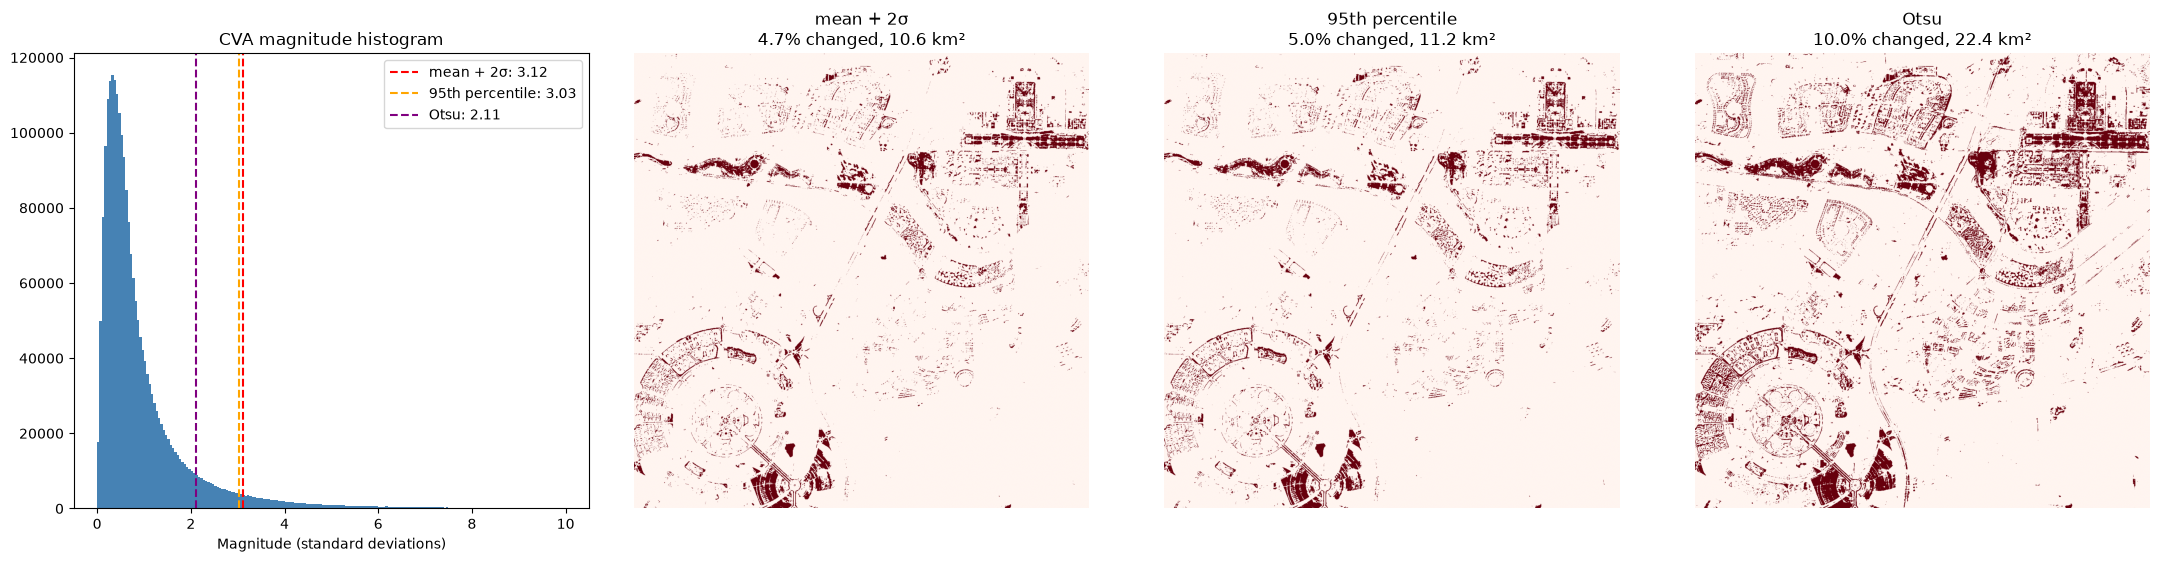

In [9]:
rules = {
    "mean + 2σ": magnitude.mean() + 2 * magnitude.std(),
    "95th percentile": np.percentile(magnitude, 95),
    "Otsu": threshold_otsu(magnitude),
}

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
axes[0].hist(magnitude.ravel(), bins=200, range=(0, 10), color="steelblue")
for (name, value), colour in zip(rules.items(), ["red", "orange", "purple"]):
    axes[0].axvline(value, color=colour, linestyle="--", label=f"{name}: {value:.2f}")
axes[0].set_title("CVA magnitude histogram")
axes[0].set_xlabel("Magnitude (standard deviations)")
axes[0].legend()

for ax, (name, value) in zip(axes[1:], rules.items()):
    mask = magnitude > value
    ax.imshow(mask, cmap="Reds")
    ax.set_title(f"{name}\n{100 * mask.mean():.1f}% changed, {mask.sum() * PIXEL_AREA_KM2:.1f} km²")
    ax.axis("off")
plt.tight_layout()
plt.show()

The three rules give clearly different answers on the same data. The histogram explains why: it has no clean gap between "unchanged" and "changed", because construction produces every degree of change, from slightly disturbed ground to a new asphalt road. Otsu places its threshold lowest here and flags the most area, while the percentile rule flags exactly 5% by definition, whether 1% or 30% of the scene really changed. None of them is "correct"; each encodes an assumption. In a real project you would check the candidates against a few locations you know (for example from very high-resolution basemap imagery), or tune the threshold on labeled reference data, as page 8 of this lesson does.

### G. The limit of pixel-wise methods

Connected change regions: 12,478
Regions of a single pixel: 4,308 (35% of all regions)
Regions smaller than 5 pixels (500 m²): 63%


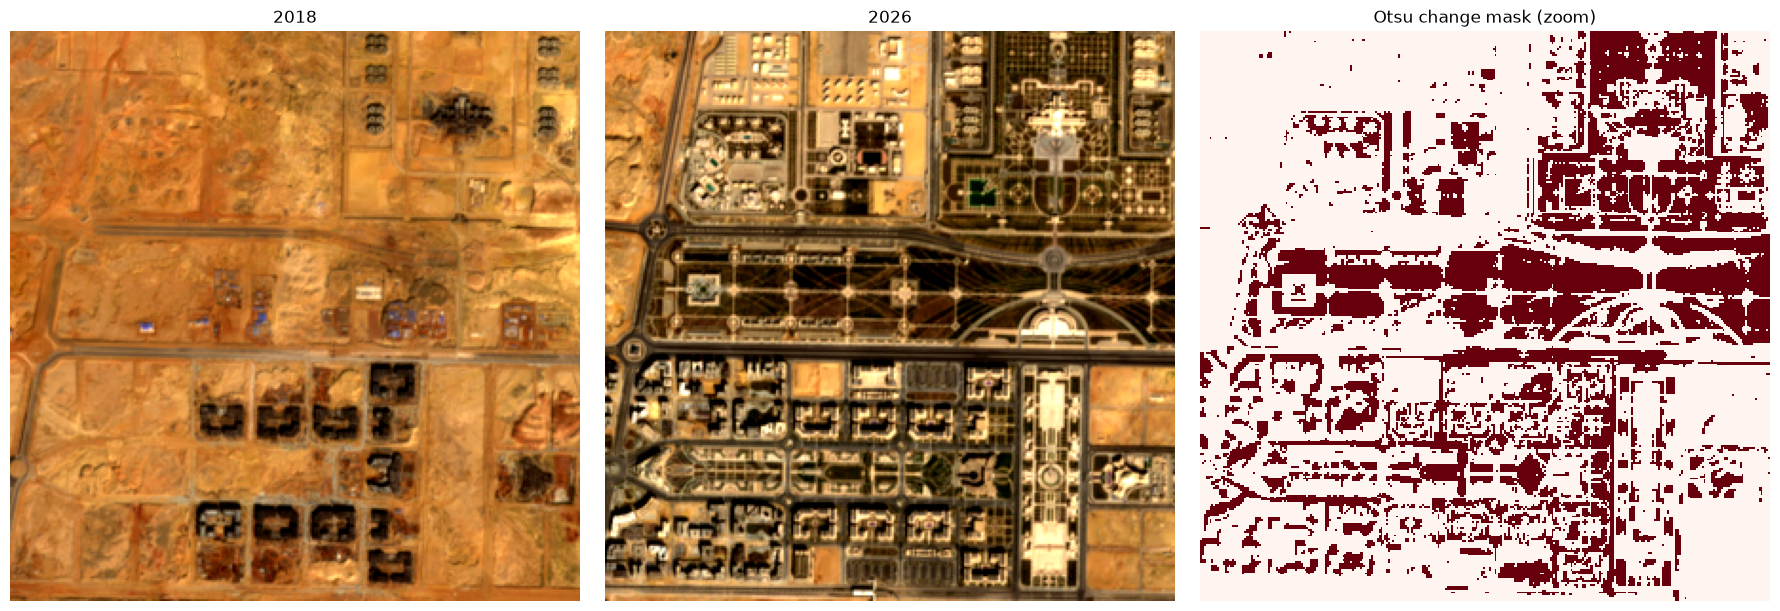

In [10]:
mask = magnitude > rules["Otsu"]
labels, n_regions = ndimage.label(mask)
sizes = np.bincount(labels.ravel())[1:]  # pixels per connected region

print(f"Connected change regions: {n_regions:,}")
print(f"Regions of a single pixel: {np.sum(sizes == 1):,} ({100 * np.mean(sizes == 1):.0f}% of all regions)")
print(f"Regions smaller than 5 pixels (500 m²): {100 * np.mean(sizes < 5):.0f}%")

rows, cols = slice(150, 450), slice(1050, 1350)  # a 3 x 3 km window
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(true_colour(img_2018, lo, hi)[rows, cols])
axes[0].set_title("2018")
axes[1].imshow(true_colour(img_2026, lo, hi)[rows, cols])
axes[1].set_title("2026")
axes[2].imshow(mask[rows, cols], cmap="Reds", interpolation="nearest")
axes[2].set_title("Otsu change mask (zoom)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Zoomed in, the mask looks speckled: a "salt-and-pepper" pattern of isolated pixels alongside the coherent blocks of real construction. A large share of all detected regions are single pixels. The method cannot tell them apart, because it never looks at a pixel's neighbours: an isolated noisy pixel and a pixel in the middle of a new district are judged by exactly the same rule. You could clean the mask afterwards (for example by removing regions below a minimum size), but that is a post-processing fix, not an understanding of the scene. Using spatial context directly is what the deep learning approaches on the next page are designed to do.

---

## 4. Python reactivation

- `np.median(diff)`, `np.std(diff)`, `np.percentile(magnitude, 95)` and `threshold_otsu(magnitude)` are summary statistics used directly as centring and thresholding rules.
- `img_2018.mean(axis=0)` averages over the first axis (the bands), giving one brightness value per pixel.
- `np.hypot(x, y)` computes the length of a vector, $\sqrt{x^2 + y^2}$; `np.arctan2(y, x)` computes its angle, the standard way to get a direction from a two-dimensional vector, and `np.degrees()` converts that angle from radians to degrees.
- `np.select(conditions, choices, default)` assigns a value per pixel from the first condition that is true, a compact alternative to nested `np.where` calls.
- `ndimage.label(mask)` gives every connected group of `True` pixels its own integer ID, and `np.bincount` then counts the pixels per ID.

---

## 5. Common pitfalls

- **Treating the threshold as a fixed, universal setting.** Step F shows three reasonable rules giving very different changed areas on the same data. Always inspect the histogram, and check candidate thresholds against known locations.
- **Using only one band when multi-band information is available.** CVA's direction adds real interpretive value over single-band differencing whenever you have more than one comparable band.
- **Combining measurements with different units without rescaling.** Brightness and NDVI differences live on different scales; convert them to z-scores before computing a CVA magnitude or direction.
- **Mixing up 1-based band numbers and 0-based array positions.** Rasterio's `src.read(4)` is the NIR band, but in the NumPy array that band is `img[3]`. Named constants such as `NIR = 3` prevent this mistake.
- **Stretching each date separately for display.** Separate stretches hide whole-scene brightness and colour shifts, and make the two images look more comparable than they are.
- **Forgetting these methods are pixel-independent.** Neither technique uses spatial context, so isolated noisy pixels are flagged just like real change (step G).
- **Skipping the comparability checks from the previous page.** Traditional methods are especially sensitive to co-registration, illumination and phenological mismatches, since they have no learned context to fall back on.

---

## 6. Mini task

In step C, what happens to the number of changed pixels if you change the threshold from `2 * std` to `1 * std`? Reason through the direction of the change before you run it. Then make the change, and compare the new mask with the old one: does the additional area look like real construction, or like noise?

:::{dropdown} Sample solution
:class: note

Lowering the threshold from 2 to 1 standard deviation makes the criterion for "changed" easier to satisfy, so `change_mask.sum()` increases substantially: more pixels with moderate differences now exceed the lower bar.

```python
threshold = 1 * std
change_mask = np.abs(diff - centre) > threshold
print(f"{100 * change_mask.mean():.1f}% changed")
```

With these data, the changed share roughly quadruples, from about 6% to about 24% of the scene. Part of the added area fills in the new districts (building edges, gardens, partly built plots), which is genuine change the stricter threshold missed. But a lot of it is speckle spread across the whole scene, and in the southeast entire patches of open desert now count as "changed": the large-area brightness shift you saw in step C is big enough to cross the lower threshold. This is the threshold trade-off from step F in practice: more genuine change detected, at the price of many more false alarms.
:::

---

## 7. Key takeaways

- Image differencing subtracts one band between two dates and thresholds the result; it is simple, interpretable and needs no training data.
- Index differencing narrows the question: ΔNDVI finds new vegetation very well, but is blind to roads and buildings.
- Change Vector Analysis combines several measurements (here brightness and greenness); its magnitude measures how much a pixel changed, and its direction hints at the type of change.
- Different thresholding rules (standard deviations, percentiles, Otsu) can give very different changed areas on the same data; inspect the histogram and check against known locations.
- All pixel-wise methods ignore spatial context and produce salt-and-pepper noise, which motivates the deep learning approaches on the next page.

### Further reading

- OpenGeoAI, ["Change Detection"](https://opengeoai.org/examples/change_detection/) — a related worked example of change detection with `geoai`.
- scikit-image, ["Thresholding"](https://scikit-image.org/docs/stable/auto_examples/segmentation/plot_thresholding.html) — a visual comparison of Otsu and other automatic thresholding methods.
- ESA, ["Sentinel-2 User Guide"](https://sentiwiki.copernicus.eu/web/s2-mission) — band definitions, resolutions and processing levels of the Sentinel-2 imagery used on this page.